## Exploratory Data Analysis (EDA)

In [1]:
from src.data_processing import analyze_data, load_data
from src.visualization import plot_numerical_distribution, plot_categorical_distribution
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

The dataset is provided in CSV format. I will use NumPy's `genfromtxt` function to load the training data from `data/raw/aug_train.csv`.

In [2]:
train_data, headers_train_data = analyze_data('../data/raw/aug_train.csv')

====== Intitalizing file: ../data/raw/aug_train.csv ======
  - Headers: ['enrollee_id' 'city' 'city_development_index' 'gender'
 'relevent_experience' 'enrolled_university' 'education_level'
 'major_discipline' 'experience' 'company_size' 'company_type'
 'last_new_job' 'training_hours' 'target']

  - Shape: (19158, 14)

  - Data types: [(np.str_('enrollee_id'), 'i8'), (np.str_('city'), 'U8'), (np.str_('city_development_index'), 'f8'), (np.str_('gender'), 'U6'), (np.str_('relevent_experience'), 'U23'), (np.str_('enrolled_university'), 'U16'), (np.str_('education_level'), 'U14'), (np.str_('major_discipline'), 'U15'), (np.str_('experience'), 'U3'), (np.str_('company_size'), 'U9'), (np.str_('company_type'), 'U19'), (np.str_('last_new_job'), 'U5'), (np.str_('training_hours'), 'i8'), (np.str_('target'), 'f8')]

  - First 5 rows of data:
 [['8949' 'city_103' '0.92' 'Male' 'Has relevent experience'
  'no_enrollment' 'Graduate' 'STEM' '>20' '' '' '1' '36' '1.0']
 ['29725' 'city_40' '0.775999999

### aug_train.csv - Training Data Overview

Shape: 19158 samples (rows) and 14 features (columns)

Column Headers: ```enrollee_id, city, city_development_index, gender, relevent_experience, enrolled_university,
education_level, major_discipline, experience, company_size, company_type, last_new_job, training_hours, target```.

Data Types: The dataset contains a mix of numerical and categorical features.
```
- enrollee_id: i8
- city: U8
- city_development_index: f8
- gender: U6
- relevent_experience: U23
- enrolled_university: U16
- education_level: U14
- major_discipline: U15
- experience: U3
- company_size: U9
- company_type: U19
- last_new_job: U5
- training_hours: i8
- target: f8
```

Duplicate Entries: There are no duplicate rows in the dataset.

Regarding Missing Values: The dataset has a major issue with missing data, clearly divided into two groups:
- Severe Group (>14%): ```company_type (32%), company_size (31%), gender (23.5%), major_discipline (14.7%)```. This proportion is too large to discard (drop rows). Dropping these would result in losing 1/3 of your data.

Solution: Replace missing values with a new category like 'Unknown' or 'Other'.

- Mild Group (<3%): ```enrolled_university, education_level, last_new_job, experience```.

Solution: Impute with the most frequent value (Mode).

Regarding Categorical Variables: In the city column, there are 123 unique cities, but 106 are rare (appearing less than 1%). If using One-Hot Encoding, the model will inflate by an additional 123 columns, causing the "Curse of Dimensionality", making the model slow and prone to Overfitting.

Solution: Keep the Top 10-20 most common cities, and group all those 106 rare cities into a single category called 'Other_City'.

- Regarding Numerical Variables & Outliers
In the training_hours column: Range is from -74.5 to 185.5 (based on IQR calculation), but the actual max is 336. This is not necessarily noise but rather a Right-skewed distribution. A small number of people study very intensively.

Solution: Do not delete these high-intensity learners as they might be a significant group. Consider Log transformation to reduce the impact of these extreme values.

In the target column: Statistics show ```Range: [0, 0]``` and ```Outliers count: 4777``` (Min/Max outlier is 1). This means the count of label 0 is overwhelmingly dominant. The outlier detection algorithm (usually IQR-based) considers 0 as normal and treats all instances of 1 as "outliers". The data suffers from Severe Class Imbalance.

Solution: Use Downsampling techniques.

In [3]:
test_data, headers_test_data = analyze_data('../data/raw/aug_test.csv')

====== Intitalizing file: ../data/raw/aug_test.csv ======
  - Headers: ['enrollee_id' 'city' 'city_development_index' 'gender'
 'relevent_experience' 'enrolled_university' 'education_level'
 'major_discipline' 'experience' 'company_size' 'company_type'
 'last_new_job' 'training_hours']

  - Shape: (2129, 13)

  - Data types: [(np.str_('enrollee_id'), 'i8'), (np.str_('city'), 'U8'), (np.str_('city_development_index'), 'f8'), (np.str_('gender'), 'U6'), (np.str_('relevent_experience'), 'U23'), (np.str_('enrolled_university'), 'U16'), (np.str_('education_level'), 'U14'), (np.str_('major_discipline'), 'U15'), (np.str_('experience'), 'U3'), (np.str_('company_size'), 'U9'), (np.str_('company_type'), 'U19'), (np.str_('last_new_job'), 'U5'), (np.str_('training_hours'), 'i8')]

  - First 5 rows of data:
 [['32403' 'city_41' '0.8270000000000001' 'Male' 'Has relevent experience'
  'Full time course' 'Graduate' 'STEM' '9' '<10' '' '1' '21']
 ['9858' 'city_103' '0.92' 'Female' 'Has relevent experien

### aug_test.csv - Test Data Overview

Shape: 2129 samples (rows) and 13 features (columns)

Column Headers: ```enrollee_id, city, city_development_index, gender, relevent_experience, enrolled_university,
education_level, major_discipline, experience, company_size, company_type, last_new_job, training_hours```.

Data Types: The dataset contains a mix of numerical and categorical features.
```
- enrollee_id: i8
- city: U8
- city_development_index: f8
- gender: U6
- relevent_experience: U23
- enrolled_university: U16
- education_level: U14
- major_discipline: U15
- experience: U3
- company_size: U9
- company_type: U19
- last_new_job: U5
- training_hours: i8
```

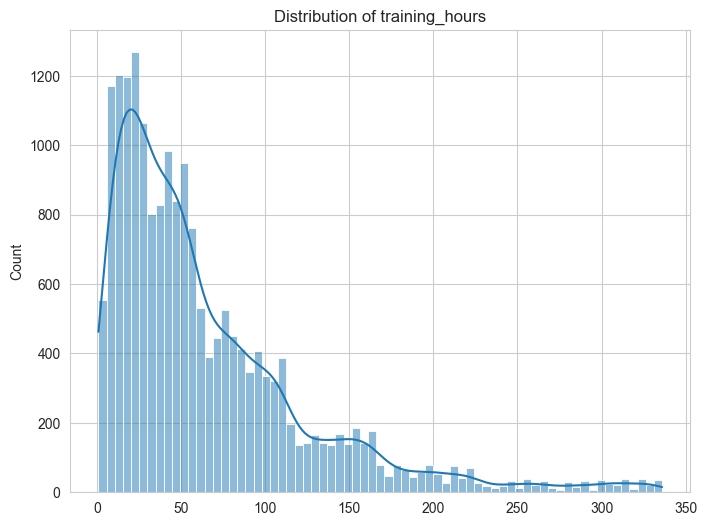

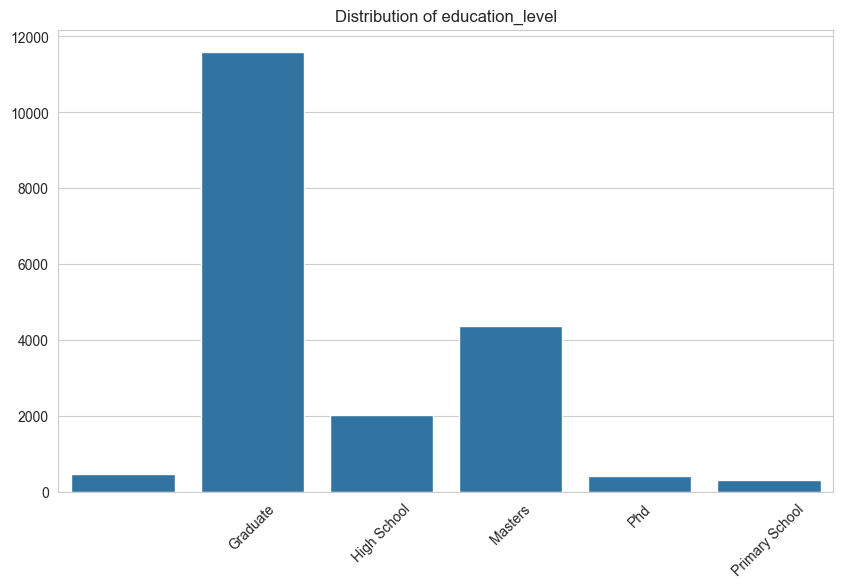

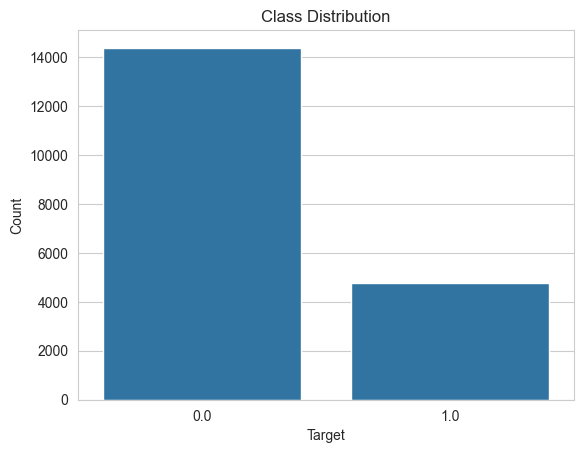

In [5]:
train_data, test_data = load_data('../data/raw/aug_train.csv', '../data/raw/aug_test.csv')

# Plot distributions
plot_numerical_distribution(train_data, 'training_hours')
plot_categorical_distribution(train_data, 'education_level')

unique, counts = np.unique(train_data['target'], return_counts=True)
sns.barplot(x=unique, y=counts)
plt.title('Class Distribution')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()